# WattWise — Phase 3: Forecasting

**What this notebook is for:** teach the computer to predict price and carbon for the hours Octopus hasn't published yet — and prove the prediction is better than a dumb guess.

**The honest rule of forecasting:** you train on the PAST and test on the FUTURE. We never let the model peek at the days it's being tested on. That's why we split the data by time, not randomly.

**Before you run this:** install scikit-learn once (the machine-learning library):
```
pip install scikit-learn
```
Run each cell with **Shift + Enter**, top to bottom.

## 1. Load the history and build clues ("features")

This reads the ~30 days you downloaded with `fetch_history.py`. Then we give the model clues it can learn from:

- **hour, day of week, weekend, month** — the time patterns (e.g. the 4–7pm peak).
- **lag1** = the value 30 minutes ago.
- **lag48** = the value at *this exact time yesterday* (energy is very daily, so yesterday is a strong hint).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../backend/data/processed/history.csv", parse_dates=["timestamp_utc"])
df = df.sort_values("timestamp_utc").reset_index(drop=True)

# time features (in UK local time)
t = df["timestamp_utc"].dt.tz_convert("Europe/London")
df["hour"] = t.dt.hour
df["dow"] = t.dt.day_of_week          # 0 = Monday
df["weekend"] = (t.dt.day_of_week >= 5).astype(int)
df["month"] = t.dt.month

print(f"{len(df)} half-hourly rows, from {df['timestamp_utc'].min().date()} to {df['timestamp_utc'].max().date()}")
df.head()

1440 half-hourly rows, from 2026-10-04 to 2026-11-03


,timestamp_utc,carbon_intensity,price_p_kwh,region,data_type,hour,dow,weekend,month
0,2026-10-04 12:00:00+00:00,59,7.16,North West England,historical_actual,13,6,1,10
1,2026-10-04 12:30:00+00:00,61,6.74,North West England,historical_actual,13,6,1,10
2,2026-10-04 13:00:00+00:00,65,11.22,North West England,historical_actual,14,6,1,10
3,2026-10-04 13:30:00+00:00,61,13.46,North West England,historical_actual,14,6,1,10
4,2026-10-04 14:00:00+00:00,75,21.86,North West England,historical_actual,15,6,1,10


## 2. The dumb guess to beat

Before any machine learning, set the benchmark: **"this half-hour will be the same as the same half-hour yesterday"** (that's `lag48`). If our clever models can't beat this, they're not worth the complexity — and saying so honestly is good science.

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate(target):
    """Train models to predict `target`, test on the most recent 20% of days."""
    d = df.copy()
    d["lag1"] = d[target].shift(1)     # 30 min ago
    d["lag48"] = d[target].shift(48)   # same time yesterday
    d = d.dropna().reset_index(drop=True)

    # CHRONOLOGICAL split — train on the older 80%, test on the newest 20%
    cut = int(len(d) * 0.8)
    features = ["hour", "dow", "weekend", "month", "lag1", "lag48"]
    X_train, X_test = d[features][:cut], d[features][cut:]
    y_train, y_test = d[target][:cut], d[target][cut:]

    results = {}
    # the dumb guess: yesterday's value
    yday = d["lag48"][cut:]
    results["Baseline (yesterday)"] = (mean_absolute_error(y_test, yday),
                                       mean_squared_error(y_test, yday) ** 0.5)
    # the models, simplest first
    for name, model in [("Linear", LinearRegression()),
                        ("Random Forest", RandomForestRegressor(n_estimators=200, random_state=0)),
                        ("Gradient Boosting", GradientBoostingRegressor(random_state=0))]:
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        results[name] = (mean_absolute_error(y_test, pred),
                         mean_squared_error(y_test, pred) ** 0.5)
    return results, d, cut, features

print("Ready. MAE = average error. RMSE = error that punishes big misses. Lower = better.")

Ready. MAE = average error. RMSE = error that punishes big misses. Lower = better.


## 3. The results table

For each thing we predict (carbon, then price), this shows how far off each model is on the **held-out future** — the days it never trained on. Watch whether the models beat the Baseline row.

In [3]:
rows = []
for target in ["carbon_intensity", "price_p_kwh"]:
    results, _, _, _ = evaluate(target)
    for model_name, (mae, rmse) in results.items():
        rows.append({"target": target, "model": model_name,
                     "MAE": round(mae, 2), "RMSE": round(rmse, 2)})

scores = pd.DataFrame(rows)
display(scores.pivot(index="model", columns="target", values="MAE")
            .reindex(["Baseline (yesterday)", "Linear", "Random Forest", "Gradient Boosting"]))
print("Table above = MAE (average error). Compare each model to the Baseline row.")

target,carbon_intensity,price_p_kwh
model,,
Baseline (yesterday),35.26,2.83
Linear,4.43,1.80
Random Forest,4.89,2.42
Gradient Boosting,4.34,2.03


Table above = MAE (average error). Compare each model to the Baseline row.


## 4. See it predict — actual vs forecast

A picture of the test period: the real carbon (what happened) against the model's forecast. If the orange line tracks the green line, the model learned the daily rhythm.

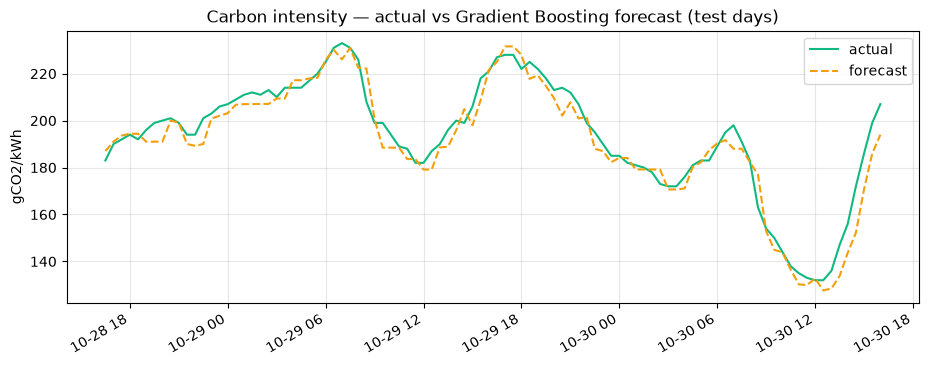

In [4]:
results, d, cut, features = evaluate("carbon_intensity")
model = GradientBoostingRegressor(random_state=0).fit(d[features][:cut], d["carbon_intensity"][:cut])
pred = model.predict(d[features][cut:])

when = d["timestamp_utc"][cut:].dt.tz_convert("Europe/London")
show = slice(0, 96)  # first 2 days of the test window, for a readable chart

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(when.values[show], d["carbon_intensity"][cut:].values[show], color="#10B981", label="actual")
ax.plot(when.values[show], pred[show], color="#F59E0B", label="forecast", linestyle="--")
ax.set_title("Carbon intensity — actual vs Gradient Boosting forecast (test days)")
ax.set_ylabel("gCO2/kWh"); ax.legend(); ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()

## 5. Your finding ✍️

Write one or two plain sentences, for example:

> All three models beat the “same as yesterday” baseline by a wide margin. For carbon, MAE fell from 35.3 to ~4.3 gCO₂/kWh (Gradient Boosting); for price, from 2.83 to 1.80 p/kWh (Linear — notably, the simplest model won). The forecast tracks the real daily peaks and troughs closely. Honest caveats: much of the carbon skill comes from the strong “value 30 minutes ago” feature, so this one-step-ahead forecast is easier than the multi-hour-ahead prediction WattWise ultimately needs; and it’s only ~30 days of one region. A genuine multi-hour horizon is the next refinement.

**Once this is written, Phase 3 is done ✅.** Commit and push, then we build Phase 4 — the optimiser that turns these forecasts into an actual appliance timetable.